# NinaPro DB5 → simulated sEMG

Simulate the EMG of a real NinaPro recording from its glove motion, and compare it with the real EMG.

In [1]:
pip install -e ../

Obtaining file:///home/marcos-oriol/Documents/thesis/simulations/myogen
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for myogen (pyproject.toml) ... done
  Created wheel for myogen: filename=myogen-0.2.0-0.editable-py3-none-any.whl size=6538 sha256=fe84c4c243c4d88c8ed01bf8392e3fcec6712b92745cfc82203d9e84afb7e99d
  Stored in directory: /tmp/pip-ephem-wheel-cache-n4zmnud6/wheels/de/f6/d9/be06e27f0f51db23b017cce013823882cb62f5bfdf8dd2f31a
Successfully built myogen
  Attempting uninstall: myogen
    Found existing installation: myogen 0.2.0
    Uninstalling myogen-0.2.0:
      Successfully uninstalled myogen-0.2.0
Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import myogen as mg

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from ninapro import glove_to_angles, subject_files

## 1. Load a recording

40 s of subject 1, exercise 2: wrist flexion then extension. All the subject's files are loaded because the glove
is normalised per subject.

In [2]:
recs = subject_files(ROOT / "data/real/ninapro_db5/s1")
rec = recs[1]                                   # S1_E2_A1.mat
fs = rec["fs"]                                  # 200 Hz (Myo armbands)
i0, i1 = int(665 * fs), int(705 * fs)
real = rec["emg"][i0:i1]                        # (8000, 16)
rest = rec["restimulus"][i0:i1] == 0

## 2. Glove → `HandMotion`

`glove_to_angles` gives `{model joint: angles (rad)}`; `JointAdapter` turns it into a `HandMotion`.

In [3]:
angles = {k: v[i0:i1] for k, v in glove_to_angles(rec, recs).items()}
motion = mg.JointAdapter()(angles, fs, rest=rest)

## 3. Simulate

`Electrodes.myo()` is the DB5 setup (two 8-channel Myo armbands), `Subject()` the average subject.

In [8]:
sim = mg.Simulator(mg.Electrodes.myo(), subject=mg.Subject())
recording = sim.run(motion)                     # ~0.5 s of compute per s of motion
print("QC pass:", recording.qc["pass"], f"(tracking RMSE {recording.qc['rmse_deg']:.2f} deg)")

path = recording.save(ROOT / "data/synthetic/notebook_ninapro_analytic.h5")   # mg.Recording.load(path)

QC pass: True (tracking RMSE 0.51 deg)


## 4. Real vs simulated

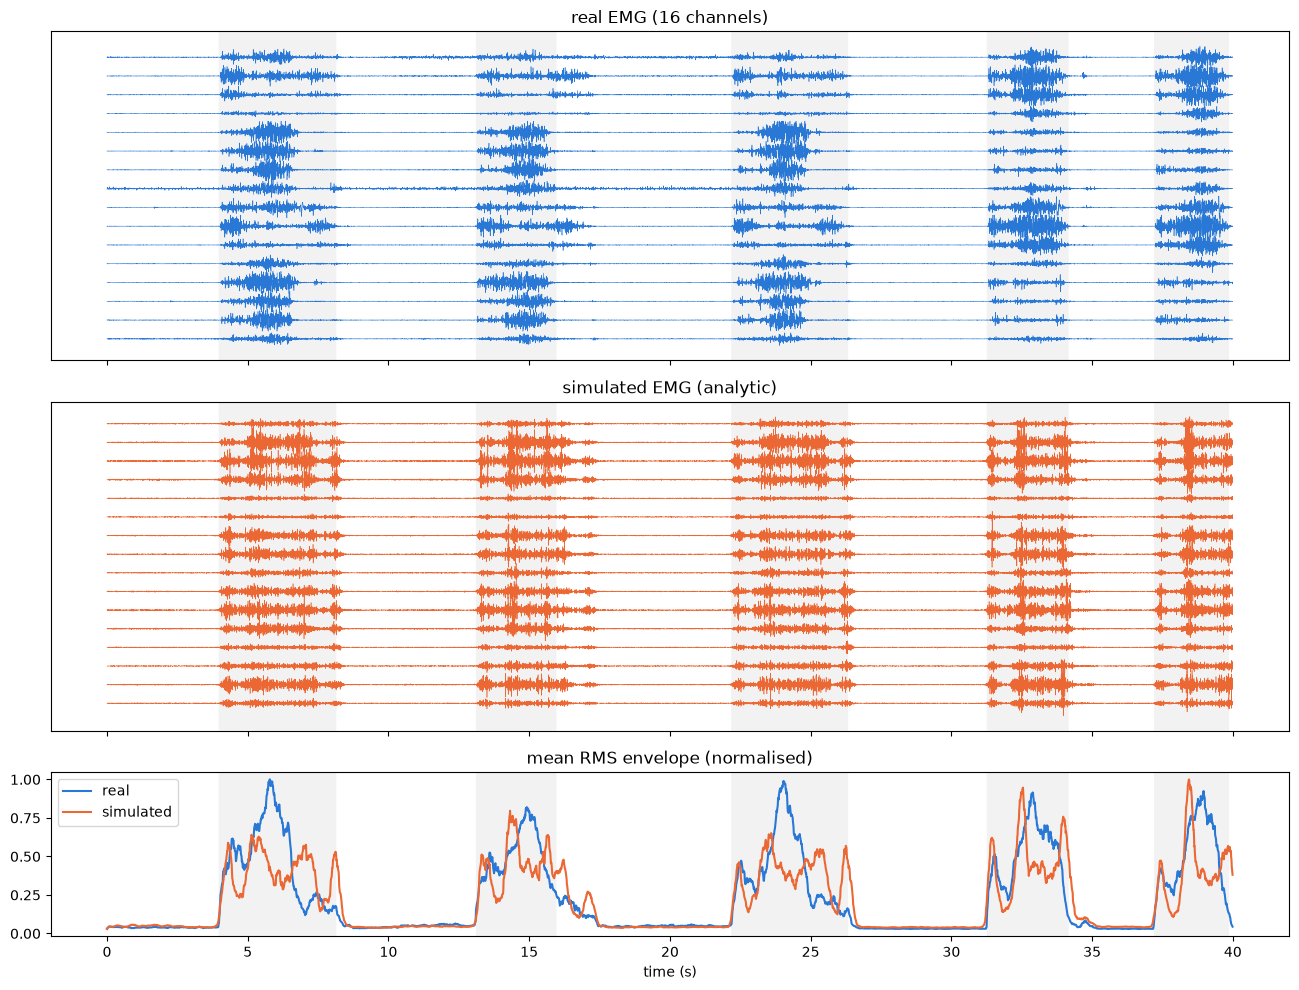

In [9]:
REAL, SIM = "#2a78d6", "#eb6834"
t = np.arange(len(real)) / fs
env = lambda x: mg.calibration.envelope(x, fs, "myo").mean(1)
te = np.arange(len(env(real))) / mg.calibration.ENV_FS


def traces(ax, x, color, title):
    off = 2.5 * np.percentile(np.abs(x), 99)
    for c in range(x.shape[1]):
        ax.plot(t, x[:, c] - c * off, color=color, lw=0.4)
    ax.set(title=title, yticks=[])


fig, ax = plt.subplots(3, 1, figsize=(13, 10), sharex=True, gridspec_kw={"height_ratios": [3, 3, 1.5]})
traces(ax[0], real, REAL, "real EMG (16 channels)")
traces(ax[1], recording.emg.astype(float), SIM, "simulated EMG (analytic)")
ax[2].plot(te, env(real) / env(real).max(), color=REAL, label="real")
ax[2].plot(te, env(recording.emg) / env(recording.emg).max(), color=SIM, label="simulated")
ax[2].set(title="mean RMS envelope (normalised)", xlabel="time (s)")
ax[2].legend()
for a in ax:
    a.fill_between(t, 0, 1, where=~rest, transform=a.get_xaxis_transform(), color="0.5", alpha=0.1, lw=0)
fig.tight_layout()

Grey: labelled movement. To see the hand, electrodes and muscles move in 3-D, run in a terminal:

```bash
myogen replay data/synthetic/notebook_ninapro_analytic.h5      # http://localhost:8080
```